# SFT vs DPO vs SFT -> DPO
Same data, split, prompt, 1,000 test sentences and metrics as Task 1. Results and judgement are in the README.

## 1. Setup

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [ ]:
!pip install -q -U transformers datasets peft trl bitsandbytes accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import transformers, trl, peft, torch
print(transformers.__version__, trl.__version__, peft.__version__, torch.__version__)
transformers.set_seed(42)

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, HfApi
login(token=UserSecretsClient().get_secret("HF_TOKEN"))

SFT_REPO = "AadarshKr/qwen2.5-1.5b-ade-lora"
DPO_REPO = "AadarshKr/qwen2.5-1.5b-ade-dpo"

# Creating a new repo for DPO Adapters
HfApi().create_repo(DPO_REPO, private = True, exist_ok = True)

5.22.2 1.17.1 0.21.2 2.11.0+cu130


RepoUrl('https://huggingface.co/AadarshKr/qwen2.5-1.5b-ade-dpo', endpoint='https://huggingface.co', repo_type='model', repo_id='AadarshKr/qwen2.5-1.5b-ade-dpo')

## 2. Data (same split as Task 1)

In [ ]:
from datasets import load_dataset
import pandas as pd
from sklearn.model_selection import train_test_split

# Loading the dataset
clf_df = load_dataset("ade-benchmark-corpus/ade_corpus_v2", "Ade_corpus_v2_classification")["train"].to_pandas()
rel_df = load_dataset("ade-benchmark-corpus/ade_corpus_v2", "Ade_corpus_v2_drug_ade_relation")["train"].to_pandas()

# Unique record per sentence
uniq_clf_df = clf_df.drop_duplicates(subset = "text")
grouped_rel_df = (
    rel_df
    .drop_duplicates(subset = ["text", "drug", "effect"])
    .groupby("text")
    .apply(lambda x:x[["drug", "effect"]].to_dict(orient = "records"), include_groups = False)
    .reset_index(name = "pairs")
)

records = uniq_clf_df.merge(grouped_rel_df, on = "text", how = "left")
records["pairs"] = records["pairs"].apply(lambda v:v if isinstance(v, list) else[])

# Train, Validation and Test splitting
temp_df, test_df = train_test_split(records, test_size = 1000, stratify = records["label"], random_state = 42)
train_df, val_df = train_test_split(temp_df, test_size = 500, stratify = temp_df["label"], random_state = 42)

print(len(train_df), len(test_df), len(val_df), "| test ADE %:", round(test_df["label"].mean() * 100, 1))

README.md:   0%|          | 0.00/10.2k [00:00<?, ?B/s]

Ade_corpus_v2_classification/train-00000(…): reconstructing file:   0%|          |  0.00B / 1.71MB            

Ade_corpus_v2_classification/train-00000(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23516 [00:00<?, ? examples/s]

Ade_corpus_v2_drug_ade_relation/train-00(…): reconstructing file:   0%|          |  0.00B /  491kB            

Ade_corpus_v2_drug_ade_relation/train-00(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6821 [00:00<?, ? examples/s]

19396 1000 500 | test ADE %: 20.4


In [ ]:
import json

SYSTEM_PROMPT = (
    "You are a pharmacovigilance assistant. Read the sentence and decide whether it "
    "describes an adverse drug event (ADE): a harmful effect caused by a drug. "
    "If it does, list every (drug, effect) pair. "
    "Copy the drug and the effect exactly as they are written in the sentence. "
    "If there is no ADE, return an empty list of pairs. "
    'Return only JSON in this exact format: {"has_ade": true or false, "pairs": [{"drug": "...", "effect": "..."}]}'
)

# Making the answers to feed into model to learn
def make_target(row):
    return json.dumps({"has_ade": bool(row["label"]), "pairs": row["pairs"]}, ensure_ascii = False)

# Making the question
def make_prompt(text):
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": "Sentence: "+ text}
    ]

# Adding two new column prompt and target to have question and answer.
for df in (train_df, test_df, val_df):
    df["prompt"] = df["text"].apply(make_prompt)
    df["target"] = df.apply(make_target, axis = 1)

Test mode switch: `True` = small dry run, `False` = full run.

In [ ]:
TEST_MODE = False                                   # set False for the real run
N_PER_CLASS = 20 if TEST_MODE else 1250            # preference sentences per class (ADE / non-ADE)
test_df = test_df.head(50 if TEST_MODE else 1000)
val_df = val_df.head(30 if TEST_MODE else 500)
print("mode:", "TEST" if TEST_MODE else "FULL", "| pref sentences:", 2 * N_PER_CLASS,
      "| val:", len(val_df), "| test:", len(test_df))

mode: FULL | pref sentences: 2500 | val: 500 | test: 1000


## 3. Model and generation

In [ ]:
import gc, time, re
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
bnb_config = BitsAndBytesConfig(
    load_in_4bit = True,
    bnb_4bit_quant_type = "nf4",
    bnb_4bit_use_double_quant = True,
    bnb_4bit_compute_dtype = torch.float16
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def load_base():
    return AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config = bnb_config,
        device_map = {"":0},
        torch_dtype = torch.float16
)

def generate_answers(model, prompts, batch_size = 16, max_new_tokens = 512):
        tokenizer.padding_side = "left"
        model.eval()
        outputs = []
        for i in range(0, len(prompts), batch_size):
            batch = prompts[i:i+batch_size]
            texts = [tokenizer.apply_chat_template(p, tokenize = False, add_generation_prompt = True) for p in batch]
            enc = tokenizer(texts, return_tensors = "pt", padding = True).to(model.device)
            with torch.no_grad():
                gen = model.generate(**enc, max_new_tokens = max_new_tokens, do_sample = False, pad_token_id = tokenizer.pad_token_id)

            outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens= True)
            print(f"{min(i + batch_size, len(prompts))}/{len(prompts)}", end= "\r")
        return outputs

def parse_answer(text):
    try:
        obj = json.loads(text.strip())
    except json.JSONDecodeError:
        match = re.search(r"\{.*\}", text, re.DOTALL)
        if match is None:
            return None
        try:
            obj = json.loads(match.group(0))
        except json.JSONDecodeError:
            return None
    if not isinstance(obj, dict) or not isinstance(obj.get("has_ade"), bool) or not isinstance(obj.get("pairs"), list):
        return None
    for pair in obj["pairs"]:
        if not (isinstance(pair, dict) and isinstance(pair.get("drug"), str) and isinstance(pair.get("effect"), str)):
            return None
    return obj

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

## 4. Scoring

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

def norm(s):
    return " ".join(s.lower().split())

def pairs_set(pairs):
    return {(norm(x["drug"]), norm(x["effect"])) for x in pairs}

def f1(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    return (p, r, 2 * p * r / (p + r) if (p + r) else 0.0)

def lenient_counts(pred, true):
    """exact matches + boundary matches (same drug, one effect span inside the other)"""
    exact_match = len(pred & true)
    pred_left = pred - true
    true_left = set(true - pred)
    boundary_match = 0
    for pred_drug, pred_effect in pred_left:
        for t in true_left:
            if t[0] == pred_drug and (t[1] in pred_effect or pred_effect in t[1]):
                boundary_match += 1
                true_left.remove(t)
                break
    return exact_match, boundary_match

def score(outputs, gold_df):
    parsed = [parse_answer(o) for o in outputs]
    y_true = gold_df["label"].astype(int).tolist()
    y_pred = [int(p["has_ade"]) if p is not None else 0 for p in parsed]
    p_ade, r_ade, f_ade, _ = precision_recall_fscore_support(y_true, y_pred, average = "binary", zero_division = 0)

    tp = fp = fn = tp_len = 0
    for p, gold_pairs in zip(parsed, gold_df["pairs"]):
        pred = pairs_set(p["pairs"]) if p is not None else set()
        true = pairs_set(gold_pairs)
        tp += len(pred & true)
        fp += len(pred - true)
        fn += len(true - pred)
        exact_match, boundary_match = lenient_counts(pred,true)
        tp_len += exact_match + boundary_match

    n_pred = tp + fp
    n_true = tp + fn
    p_pair, r_pair, f_pair = f1(tp,fp,fn)
    f_len = f1(tp_len, n_pred - tp_len, n_true - tp_len)[2]

    return {
        "json_valid_%": round(100 * sum(p is not None for p in parsed) / len(parsed), 1),
        "ade_precision": round(p_ade, 3), "ade_recall": round(r_ade, 3), "ade_f1": round(f_ade, 3),
        "pair_precision": round(p_pair, 3), "pair_recall": round(r_pair, 3), "pair_f1": round(f_pair, 3),
        "pair_f1_lenient": round(f_len, 3),
        "false_alarms": sum(1 for t, p in zip(y_true, y_pred) if p == 1 and t == 0),
        "misses": sum(1 for t, p in zip(y_true, y_pred) if p == 0 and t == 1),
    }

def is_correct(output, row):
    p = parse_answer(output)
    return p is not None and p["has_ade"] == bool(row["label"]) and pairs_set(p["pairs"]) == pairs_set(row["pairs"])

RESULTS = {}
OUTPUTS = {}

def evaluate(model,name):
    t0 = time.time()
    out = generate_answers(model, test_df["prompt"].tolist())
    m = score(out, test_df)
    m["eval_seconds"] = round(time.time() - t0)
    RESULTS[name], OUTPUTS[name] = m, out
    print("\n", name, m)
    with open("dpo_results.json", "w") as f:
        json.dump({"metrics": RESULTS, "outputs": OUTPUTS, "test_text": test_df["text"].tolist()}, f)
    HfApi().upload_file(path_or_fileobj = "dpo_results.json", path_in_repo = "dpo_results.json", repo_id = DPO_REPO)
    return m

## 5. Evaluate Base and SFT, collect their answers for the preference pairs

In [ ]:
from peft import PeftModel

pref_df = pd.concat([
    train_df[train_df["label"] == 1].sample(N_PER_CLASS, random_state = 42),
    train_df[train_df["label"] == 0].sample(N_PER_CLASS, random_state = 42)
]).sample(frac = 1, random_state = 42).reset_index(drop = True)

model = load_base()

sft_model = PeftModel.from_pretrained(model, SFT_REPO)
sft_model.config.use_cache = True

evaluate(sft_model, "A. SFT only")
t0 = time.time()
sft_train_out = generate_answers(sft_model, pref_df["prompt"].tolist())
sft_val_out = generate_answers(sft_model, val_df["prompt"].tolist())
print("\nSFT answers on pref + val sentences:", round(time.time() - t0), "s")

with sft_model.disable_adapter():
    evaluate(sft_model, "Base (no training)")
    base_train_out = generate_answers(sft_model, pref_df["prompt"].tolist())
    base_val_out = generate_answers(sft_model, val_df["prompt"].tolist())

with open("pref_generations.json", "w") as f:
    json.dump({"text": pref_df["text"].tolist(), "base": base_train_out, "sft": sft_train_out,
               "val_text": val_df["text"].tolist(), "base_val": base_val_out, "sft_val": sft_val_out}, f)
HfApi().upload_file(path_or_fileobj="pref_generations.json", path_in_repo="pref_generations.json", repo_id=DPO_REPO)

del sft_model, model
gc.collect()
torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

adapter_config.json:   0%|          | 0.00/1.18k [00:00<?, ?B/s]

adapter_model.safetensors: reconstructing file:   0%|          |  0.00B / 73.9MB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

1000/1000
 A. SFT only {'json_valid_%': 100.0, 'ade_precision': 0.932, 'ade_recall': 0.877, 'ade_f1': 0.904, 'pair_precision': 0.701, 'pair_recall': 0.694, 'pair_f1': 0.697, 'pair_f1_lenient': 0.779, 'false_alarms': 13, 'misses': 25, 'eval_seconds': 396}
500/500
SFT answers on pref + val sentences: 1506 s
1000/1000
 Base (no training) {'json_valid_%': 99.7, 'ade_precision': 0.4, 'ade_recall': 0.824, 'ade_f1': 0.538, 'pair_precision': 0.178, 'pair_recall': 0.489, 'pair_f1': 0.261, 'pair_f1_lenient': 0.322, 'false_alarms': 252, 'misses': 36, 'eval_seconds': 283}


## 6. Preference pairs (chosen = gold, rejected = model's mistake or a corruption)

In [ ]:
import random
rng = random.Random(42)

def corrupt(row):
    """A realistic wrong answer when the model was already right (mimics the Task 1 error types)."""
    words = row["text"].split()
    pairs = [dict(p) for p in row["pairs"]]
    if not row["label"]:                          # false alarm: invent a pair from words in the sentence
        i, j = rng.sample(range(len(words)), 2) if len(words) > 1 else (0, 0)
        return {"has_ade": True, "pairs": [{"drug": words[i].strip(".,;()"), "effect": words[j].strip(".,;()")}]}
    options = ["miss_ade", "drop_pair", "swap"]
    if any(len(p["effect"].split()) > 1 for p in pairs):
        options.append("shorten")
    kind = rng.choice(options)
    if kind == "miss_ade":                        # say no ADE
        return {"has_ade": False, "pairs": []}
    if kind == "drop_pair":                       # miss one pair
        pairs.pop(rng.randrange(len(pairs)))
    elif kind == "swap":                          # drug and effect swapped
        k = rng.randrange(len(pairs)); pairs[k] = {"drug": pairs[k]["effect"], "effect": pairs[k]["drug"]}
    else:                                         # span boundary error
        k = rng.choice([i for i, p in enumerate(pairs) if len(p["effect"].split()) > 1])
        pairs[k]["effect"] = " ".join(pairs[k]["effect"].split()[1:])
    return {"has_ade": True, "pairs": pairs}

def build_pairs(df, own_outputs):
    rows, n_real = [], 0
    for (_, row), out in zip(df.iterrows(), own_outputs):
        if is_correct(out, row):
            rejected = json.dumps(corrupt(row), ensure_ascii=False)
        else:
            rejected = out.strip()[:2000]; n_real += 1
        rows.append({"prompt": row["prompt"],
                     "chosen": [{"role": "assistant", "content": row["target"]}],
                     "rejected": [{"role": "assistant", "content": rejected}]})
    print(f"{n_real}/{len(rows)} rejected answers are the model's own mistakes; the rest are corruptions")
    return rows

from datasets import Dataset
# training pairs from the 2,500 training sentences; validation pairs from the 500 validation sentences
print("B train:", end=" "); b_train = Dataset.from_list(build_pairs(pref_df, base_train_out))
print("B val:  ", end=" "); b_eval  = Dataset.from_list(build_pairs(val_df,  base_val_out))
print("C train:", end=" "); c_train = Dataset.from_list(build_pairs(pref_df, sft_train_out))
print("C val:  ", end=" "); c_eval  = Dataset.from_list(build_pairs(val_df,  sft_val_out))
print(b_train[0]["chosen"][0]["content"], "\nvs\n", b_train[0]["rejected"][0]["content"][:300])

B train: 1289/2500 rejected answers are the model's own mistakes; the rest are corruptions
B val:   190/500 rejected answers are the model's own mistakes; the rest are corruptions
C train: 375/2500 rejected answers are the model's own mistakes; the rest are corruptions
C val:   52/500 rejected answers are the model's own mistakes; the rest are corruptions
{"has_ade": false, "pairs": []} 
vs
 ```json
{"has_ade": true, "pairs": [{"drug": "antisynthetase syndrome", "effect": "fibrosing alveolitis"}, {"drug": "antisynthetase syndrome", "effect": "drug-induced"}]}
```


## 7. DPO settings (same for B and C)

In [ ]:
from peft import LoraConfig
from trl import DPOConfig, DPOTrainer

def dpo_args(out_dir):
    steps = max(1, len(b_train) // 16)
    args = DPOConfig(
        output_dir=out_dir,
        beta=0.1,
        learning_rate=2e-5,
        num_train_epochs=1,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=8,          # effective batch 16
        per_device_eval_batch_size=2,
        lr_scheduler_type="cosine",
        warmup_steps=max(1, steps // 10),
        max_length=1024,
        logging_steps=10,
        eval_strategy="steps", eval_steps=50 if not TEST_MODE else 1,
        save_strategy="no",
        fp16=True, bf16=False,                  # T4
        gradient_checkpointing=True,
        report_to="none",
    )
    args._n_gpu = 1
    return args

lora_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
                         task_type="CAUSAL_LM")

def to_fp32(trainer):
    # keep trainable LoRA weights in float32: small DPO updates vanish in 16-bit (same fix as Task 1)
    for _, p in trainer.model.named_parameters():
        if p.requires_grad:
            p.data = p.data.float()
    print({str(p.dtype) for p in trainer.model.parameters() if p.requires_grad})

def save_adapter(trainer, subfolder):
    trainer.model.save_pretrained(subfolder, selected_adapters=["default"])
    HfApi().upload_folder(folder_path=subfolder, path_in_repo=subfolder, repo_id=DPO_REPO)

TRAIN_LOG = {}

## 8. B: DPO only (new LoRA on base, reference = base)

In [ ]:
tokenizer.padding_side = "right"
model = load_base()
trainer_b = DPOTrainer(model=model, args=dpo_args("dpo-only"), train_dataset=b_train, eval_dataset=b_eval,
                       processing_class=tokenizer, peft_config=lora_config)
trainer_b.model.print_trainable_parameters()
to_fp32(trainer_b)

t0 = time.time()
trainer_b.train()
TRAIN_LOG["B. DPO only"] = round(time.time() - t0)
print("train seconds:", TRAIN_LOG["B. DPO only"])
pd.DataFrame(trainer_b.state.log_history).to_csv("log_dpo_only.csv", index=False)
save_adapter(trainer_b, "dpo-only")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/2500 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/2500 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820
{'torch.float32'}


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
50,0.026169,0.007901,0.075200,290708.000000,-1.627485,-2.011093,0.954093,-0.409536,-9.582638,1.000000,9.173103,-9.719691,-115.485129
100,0.007921,0.001931,0.081450,584507.000000,-1.259152,-1.705182,0.815795,-3.482852,-13.931583,1.000000,10.448731,-40.452852,-158.974575
150,0.003521,0.001742,0.085192,877523.000000,-1.260792,-1.691773,0.816491,-4.450634,-14.316207,1.000000,9.865572,-50.130676,-162.820813
157,0.003521,0.001752,0.085176,913667.000000,-1.261474,-1.692436,0.816589,-4.455889,-14.319977,1.000000,9.864088,-50.183223,-162.858514


train seconds: 1743


In [ ]:
trainer_b.model.config.use_cache = True
evaluate(trainer_b.model, "B. DPO only")
del trainer_b, model
gc.collect(); torch.cuda.empty_cache()

1000/1000
 B. DPO only {'json_valid_%': 27.7, 'ade_precision': 0.467, 'ade_recall': 0.623, 'ade_f1': 0.534, 'pair_precision': 0.171, 'pair_recall': 0.336, 'pair_f1': 0.226, 'pair_f1_lenient': 0.303, 'false_alarms': 145, 'misses': 77, 'eval_seconds': 1452}


## 9. C: SFT -> DPO (continue SFT adapter, reference = frozen SFT copy)

In [ ]:
tokenizer.padding_side = "right"
model = load_base()
policy = PeftModel.from_pretrained(model, SFT_REPO, is_trainable=True)
trainer_c = DPOTrainer(model=policy, args=dpo_args("sft-then-dpo"), train_dataset=c_train, eval_dataset=c_eval,
                       processing_class=tokenizer)
print("adapters:", list(trainer_c.model.peft_config.keys()))   # expect ['default', 'ref']
to_fp32(trainer_c)

t0 = time.time(); trainer_c.train(); TRAIN_LOG["C. SFT → DPO"] = round(time.time() - t0)
print("train seconds:", TRAIN_LOG["C. SFT → DPO"])
pd.DataFrame(trainer_c.state.log_history).to_csv("log_sft_then_dpo.csv", index=False)
save_adapter(trainer_c, "sft-then-dpo")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/2500 [00:00<?, ? examples/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/2500 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/500 [00:00<?, ? examples/s]

adapters: ['default', 'ref']
{'torch.float32'}


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Logits/chosen,Logits/rejected,Mean Token Accuracy,Rewards/chosen,Rewards/rejected,Rewards/accuracies,Rewards/margins,Logps/chosen,Logps/rejected
50,0.200152,0.142667,0.063147,283522.000000,-1.873132,-1.775307,0.991242,-0.111672,-4.804110,0.936000,4.692438,-1.517660,-74.497003
100,0.243575,0.137590,0.053456,568411.000000,-1.943217,-1.928447,0.989532,-0.142334,-5.395362,0.942000,5.253028,-1.824288,-80.409526
150,0.160949,0.128328,0.052853,852500.000000,-1.951315,-1.946186,0.990224,-0.130513,-5.440909,0.942000,5.310396,-1.706075,-80.864995
157,0.160949,0.128537,0.052855,887506.000000,-1.950205,-1.945564,0.990366,-0.130898,-5.441819,0.942000,5.310921,-1.709927,-80.874095


train seconds: 1717


In [ ]:
trainer_c.model.set_adapter("default")
trainer_c.model.config.use_cache = True
evaluate(trainer_c.model, "C. SFT → DPO")
del trainer_c, policy, model
gc.collect(); torch.cuda.empty_cache()

1000/1000
 C. SFT → DPO {'json_valid_%': 99.5, 'ade_precision': 0.723, 'ade_recall': 0.961, 'ade_f1': 0.825, 'pair_precision': 0.556, 'pair_recall': 0.775, 'pair_f1': 0.648, 'pair_f1_lenient': 0.729, 'false_alarms': 75, 'misses': 8, 'eval_seconds': 641}


## 10. Comparison

In [ ]:
TRAIN_LOG["A. SFT only"] = 3211        # Task 1 training time (54 min, 19.4k examples)
order = ["Base (no training)", "A. SFT only", "B. DPO only", "C. SFT → DPO"]
table = pd.DataFrame(RESULTS).T.loc[order]
table["train_minutes"] = [0] + [round(TRAIN_LOG[k] / 60) for k in order[1:]]
cols = ["json_valid_%", "ade_precision", "ade_recall", "ade_f1", "pair_precision", "pair_recall",
        "pair_f1", "pair_f1_lenient", "false_alarms", "misses", "train_minutes"]
table = table[cols]
table.to_csv("dpo_comparison.csv")
HfApi().upload_file(path_or_fileobj="dpo_comparison.csv", path_in_repo="dpo_comparison.csv", repo_id=DPO_REPO)
table

,json_valid_%,ade_precision,ade_recall,ade_f1,pair_precision,pair_recall,pair_f1,pair_f1_lenient,false_alarms,misses,train_minutes
Base (no training),99.7,0.400,0.824,0.538,0.178,0.489,0.261,0.322,252.0,36.0,0
A. SFT only,100.0,0.932,0.877,0.904,0.701,0.694,0.697,0.779,13.0,25.0,54
B. DPO only,27.7,0.467,0.623,0.534,0.171,0.336,0.226,0.303,145.0,77.0,29
C. SFT → DPO,99.5,0.723,0.961,0.825,0.556,0.775,0.648,0.729,75.0,8.0,29


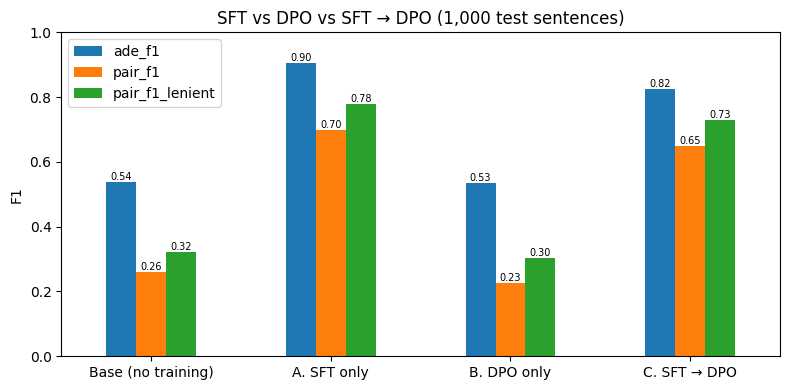

In [ ]:
import matplotlib.pyplot as plt
ax = table[["ade_f1", "pair_f1", "pair_f1_lenient"]].plot.bar(figsize=(8, 4), rot=0, ylim=(0, 1))
ax.set_title("SFT vs DPO vs SFT → DPO (1,000 test sentences)"); ax.set_ylabel("F1")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig("dpo_comparison.png", dpi=150); plt.show()

In [ ]:
# DPO training curves: did the margin between chosen and rejected grow?
for name, path in [("B. DPO only", "log_dpo_only.csv"), ("C. SFT → DPO", "log_sft_then_dpo.csv")]:
    log = pd.read_csv(path)
    cols = [c for c in ["step", "loss", "rewards/margins", "rewards/accuracies", "eval_loss", "eval_rewards/accuracies"] if c in log.columns]
    print(name); print(log[cols].dropna(how="all", subset=cols[1:]).round(3).to_string(index=False)); print()

B. DPO only
 step  loss  rewards/margins  rewards/accuracies  eval_loss  eval_rewards/accuracies
   10 0.654            0.083               0.712        NaN                      NaN
   20 0.335            1.234               0.938        NaN                      NaN
   30 0.129            3.623               0.969        NaN                      NaN
   40 0.069            4.571               0.981        NaN                      NaN
   50 0.026            6.843               1.000        NaN                      NaN
   50   NaN              NaN                 NaN      0.008                      1.0
   60 0.018            8.485               1.000        NaN                      NaN
   70 0.011            8.654               1.000        NaN                      NaN
   80 0.011            9.055               1.000        NaN                      NaN
   90 0.013            9.934               0.994        NaN                      NaN
  100 0.008           10.295               1.000     

In [ ]:
# Which errors changed between A and C? (sentences where they disagree)
a_out, c_out = OUTPUTS["A. SFT only"], OUTPUTS["C. SFT → DPO"]
fixed = [i for i in range(len(test_df)) if not is_correct(a_out[i], test_df.iloc[i]) and is_correct(c_out[i], test_df.iloc[i])]
broken = [i for i in range(len(test_df)) if is_correct(a_out[i], test_df.iloc[i]) and not is_correct(c_out[i], test_df.iloc[i])]
print("C fixed", len(fixed), "sentences that A got wrong; C broke", len(broken), "that A got right")
for i in fixed[:3] + broken[:3]:
    print("\nTEXT:", test_df.iloc[i]["text"]); print("GOLD:", test_df.iloc[i]["target"])
    print("A:", a_out[i][:300]); print("C:", c_out[i][:300])

C fixed 23 sentences that A got wrong; C broke 70 that A got right

TEXT: Theoretical basal ganglia toxicologic mechanisms of methanol poisoning are reviewed, and the role of brain imaging studies will regard to diagnosis, prognosis and impact on management is discussed.
GOLD: {"has_ade": true, "pairs": [{"drug": "methanol", "effect": "methanol poisoning"}]}
A: {"has_ade": false, "pairs": []}
C: {"has_ade": true, "pairs": [{"drug": "methanol", "effect": "methanol poisoning"}]}

TEXT: Because the cerebellar toxicity may be worsened by continuation of therapy after initial onset of symptoms, prompt termination of HDARAC is recommended.
GOLD: {"has_ade": true, "pairs": [{"drug": "HDARAC", "effect": "cerebellar toxicity"}]}
A: {"has_ade": false, "pairs": []}
C: {"has_ade": true, "pairs": [{"drug": "HDARAC", "effect": "cerebellar toxicity"}]}

TEXT: Rituximab-based therapy for gemcitabine-induced hemolytic uremic syndrome in a patient with metastatic pancreatic adenocarcinoma: a case report

## Judgement
- **SFT alone is best** (ADE F1 0.90, pair F1 0.70, 100% valid JSON).
- **DPO alone did not learn the output format** (27.7% valid JSON). Its log shows the correct answers becoming much less likely (Rewards/chosen −4.46) while it separated chosen from rejected (accuracy 1.0).
- **SFT -> DPO kept the format but shifted towards recall** (misses 25 -> 8, false alarms 13 -> 75, extra pairs; ADE F1 0.83). It fixed 23 sentences A got wrong and broke 70 that A got right.
- Possible factors for the shift, not yet tested: 85% of C's rejected answers were synthetic corruptions, the preference sample was 50/50 ADE (20% in the real data), and the DPO settings (β, learning rate) were not tuned.